In [2]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report
)
import matplotlib.pyplot as plt
import joblib

df = pd.read_csv("../data/features/customer_segments.csv")
df.head()

,CustomerID,Churn,Tenure,PreferredLoginDevice,CityTier,WarehouseToHome,PreferredPaymentMode,Gender,HourSpendOnApp,NumberOfDeviceRegistered,...,DaySinceLastOrder,CashbackAmount,AverageSpendPerOrder,EngagementScore,LoyaltyLevel,HighValueCustomer,CustomerActivity,CashbackPerOrder,Cluster,BehaviorSegment
0,50001,1,4.0,Mobile Phone,3,6.0,Debit Card,Female,3.0,3,...,5.0,159.93,79.965,5.0,New,0,2.0,79.965,4,Regular Customers
1,50002,1,9.0,Phone,1,8.0,UPI,Male,3.0,4,...,0.0,120.90,60.450,4.0,Regular,0,1.0,60.450,2,Low Engagement Customers
2,50003,1,9.0,Phone,1,30.0,Debit Card,Male,2.0,4,...,3.0,120.28,60.140,3.0,Regular,0,1.0,60.140,2,Low Engagement Customers
3,50004,1,0.0,Phone,3,15.0,Debit Card,Male,2.0,4,...,3.0,134.07,67.035,3.0,New,0,1.0,67.035,4,Regular Customers
4,50005,1,0.0,Phone,1,12.0,CC,Male,3.0,3,...,3.0,129.60,64.800,5.0,New,0,2.0,64.800,2,Low Engagement Customers


In [3]:
print(df.shape)
df.columns

(5630, 28)


Index(['CustomerID', 'Churn', 'Tenure', 'PreferredLoginDevice', 'CityTier',
       'WarehouseToHome', 'PreferredPaymentMode', 'Gender', 'HourSpendOnApp',
       'NumberOfDeviceRegistered', 'PreferedOrderCat', 'SatisfactionScore',
       'MaritalStatus', 'NumberOfAddress', 'Complain',
       'OrderAmountHikeFromlastYear', 'CouponUsed', 'OrderCount',
       'DaySinceLastOrder', 'CashbackAmount', 'AverageSpendPerOrder',
       'EngagementScore', 'LoyaltyLevel', 'HighValueCustomer',
       'CustomerActivity', 'CashbackPerOrder', 'Cluster', 'BehaviorSegment'],
      dtype='str')

In [4]:
##target separate
y = df["Churn"]
X = df.drop(columns=[
    "CustomerID",
    "Churn"
])
print(X.shape)
print(y.shape)

(5630, 26)
(5630,)


In [5]:
##encoding categorical variable
X = pd.get_dummies(
    X,
    drop_first=True
)
X.head()

,Tenure,CityTier,WarehouseToHome,HourSpendOnApp,NumberOfDeviceRegistered,SatisfactionScore,NumberOfAddress,Complain,OrderAmountHikeFromlastYear,CouponUsed,...,PreferedOrderCat_Others,MaritalStatus_Married,MaritalStatus_Single,LoyaltyLevel_New,LoyaltyLevel_Regular,LoyaltyLevel_VIP,BehaviorSegment_Low Engagement Customers,BehaviorSegment_Loyal Customers,BehaviorSegment_Regular Customers,BehaviorSegment_VIP Customers
0,4.0,3,6.0,3.0,3,2,9,1,11.0,1.0,...,False,False,True,True,False,False,False,False,True,False
1,9.0,1,8.0,3.0,4,3,7,1,15.0,0.0,...,False,False,True,False,True,False,True,False,False,False
2,9.0,1,30.0,2.0,4,3,6,1,14.0,0.0,...,False,False,True,False,True,False,True,False,False,False
3,0.0,3,15.0,2.0,4,5,8,0,23.0,0.0,...,False,False,True,True,False,False,False,False,True,False
4,0.0,1,12.0,3.0,3,5,3,0,11.0,1.0,...,False,False,True,True,False,False,True,False,False,False


In [6]:
##test split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)
print(X_train.shape)
print(X_test.shape)

(4504, 42)
(1126, 42)


In [7]:
##scaling features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [8]:
##helper function
def evaluate_model(model, X_train, X_test, y_train, y_test):
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)
    probabilities = model.predict_proba(X_test)[:,1]
    results = {
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions),
        "Recall": recall_score(y_test, predictions),
        "F1 Score": f1_score(y_test, predictions),
        "ROC AUC": roc_auc_score(
            y_test,
            probabilities
        )
    }
    return model, predictions, results

In [9]:
##logistic regression
log_model = LogisticRegression(
    random_state=42,
    class_weight="balanced",
    max_iter=1000
)

log_model, log_predictions, log_results = evaluate_model(

    log_model,

    X_train_scaled,
    X_test_scaled,

    y_train,
    y_test
)

log_results

{'Accuracy': 0.8001776198934281,
 'Precision': 0.45014245014245013,
 'Recall': 0.8315789473684211,
 'F1 Score': 0.5841035120147874,
 'ROC AUC': 0.8930105713000449}

In [10]:
##decision tree
dt_model = DecisionTreeClassifier(

    random_state=42,

    class_weight="balanced"

)

dt_model, dt_predictions, dt_results = evaluate_model(

    dt_model,

    X_train,
    X_test,

    y_train,
    y_test
)

dt_results

{'Accuracy': 0.9653641207815276,
 'Precision': 0.8871794871794871,
 'Recall': 0.9105263157894737,
 'F1 Score': 0.8987012987012987,
 'ROC AUC': 0.9435110211426001}

In [11]:
##random forest
rf_model = RandomForestClassifier(

    random_state=42,

    class_weight="balanced",

    n_estimators=200
)

rf_model, rf_predictions, rf_results = evaluate_model(

    rf_model,

    X_train,
    X_test,

    y_train,
    y_test
)

rf_results

{'Accuracy': 0.9813499111900533,
 'Precision': 0.9289340101522843,
 'Recall': 0.9631578947368421,
 'F1 Score': 0.9457364341085271,
 'ROC AUC': 0.9982849752586594}

In [12]:
##gradient boosting
gb_model = GradientBoostingClassifier(

    random_state=42

)

gb_model, gb_predictions, gb_results = evaluate_model(

    gb_model,

    X_train,
    X_test,

    y_train,
    y_test
)

gb_results

{'Accuracy': 0.9182948490230906,
 'Precision': 0.831081081081081,
 'Recall': 0.6473684210526316,
 'F1 Score': 0.727810650887574,
 'ROC AUC': 0.9400922177237966}

In [13]:
##comparing models
comparison = pd.DataFrame({

    "Logistic Regression": log_results,

    "Decision Tree": dt_results,

    "Random Forest": rf_results,

    "Gradient Boosting": gb_results

}).T

comparison

,Accuracy,Precision,Recall,F1 Score,ROC AUC
Logistic Regression,0.800178,0.450142,0.831579,0.584104,0.893011
Decision Tree,0.965364,0.887179,0.910526,0.898701,0.943511
Random Forest,0.981350,0.928934,0.963158,0.945736,0.998285
Gradient Boosting,0.918295,0.831081,0.647368,0.727811,0.940092


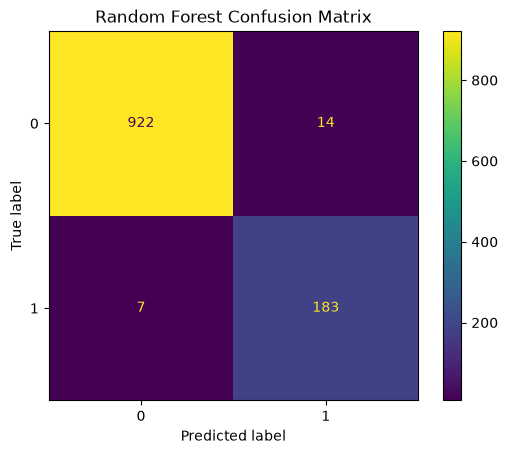

In [14]:
##confusion matrix
ConfusionMatrixDisplay.from_estimator(
    rf_model,
    X_test,
    y_test
)

plt.title("Random Forest Confusion Matrix")
plt.show()

In [15]:
##classification report
print(classification_report(
    y_test,
    rf_predictions
))

              precision    recall  f1-score   support

           0       0.99      0.99      0.99       936
           1       0.93      0.96      0.95       190

    accuracy                           0.98      1126
   macro avg       0.96      0.97      0.97      1126
weighted avg       0.98      0.98      0.98      1126



In [16]:
##feature importance
importance = pd.Series(
    rf_model.feature_importances_,
    index=X.columns
).sort_values(ascending=False)

importance.head(15)

Tenure                         0.190766
CashbackAmount                 0.070539
LoyaltyLevel_New               0.064473
Complain                       0.057254
AverageSpendPerOrder           0.055406
CashbackPerOrder               0.053856
WarehouseToHome                0.049333
DaySinceLastOrder              0.046278
NumberOfAddress                0.042056
OrderAmountHikeFromlastYear    0.037859
SatisfactionScore              0.037121
NumberOfDeviceRegistered       0.024456
CityTier                       0.020260
EngagementScore                0.019422
MaritalStatus_Single           0.018704
dtype: float64

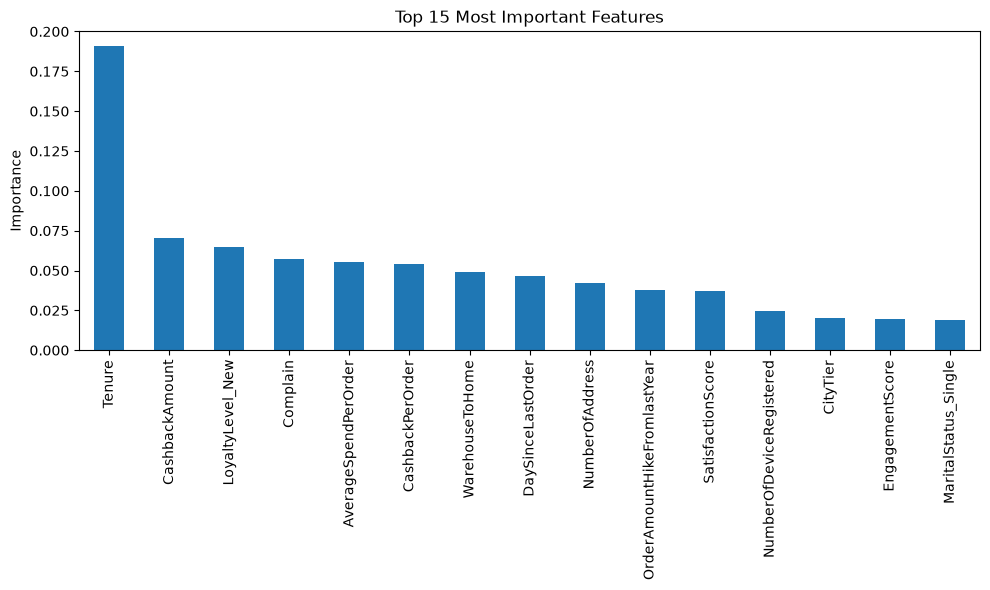

In [17]:
##plot feature importance
plt.figure(figsize=(10,6))

importance.head(15).plot(kind="bar")

plt.title("Top 15 Most Important Features")
plt.ylabel("Importance")

plt.tight_layout()
plt.show()

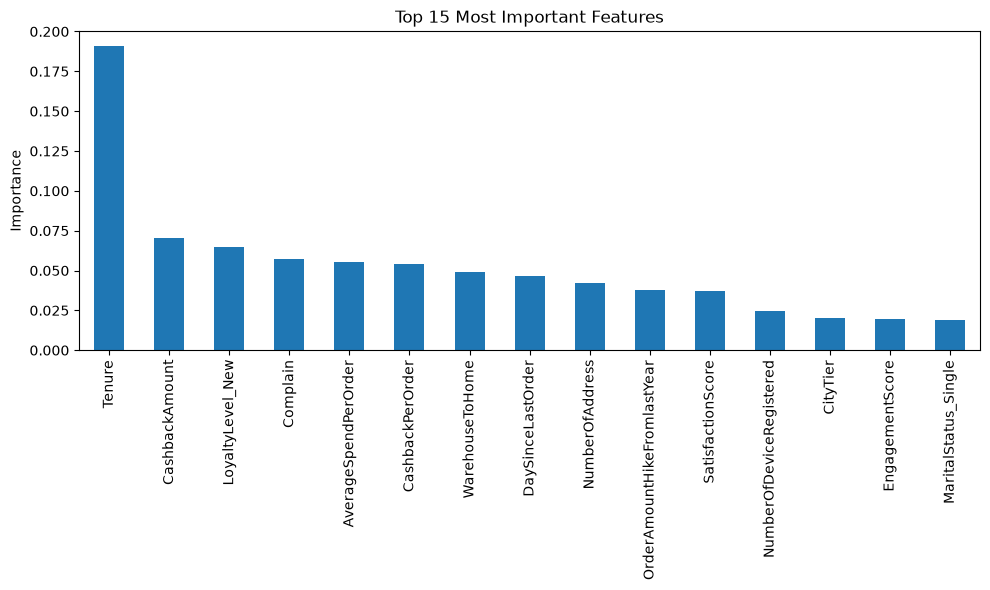

In [18]:
plt.figure(figsize=(10,6))

importance.head(15).plot(kind="bar")

plt.title("Top 15 Most Important Features")
plt.ylabel("Importance")

plt.tight_layout()
plt.show()

In [19]:
joblib.dump(
    X.columns.tolist(),
    "../artifacts/feature_names.pkl"
)

print("Feature names saved!")

Feature names saved!


In [20]:
import joblib
joblib.dump(
    rf_model,
    "../artifacts/churn_model.pkl"
)

joblib.dump(
    scaler,
    "../artifacts/scaler.pkl"
)

joblib.dump(
    X.columns.tolist(),
    "../artifacts/feature_names.pkl"
)

print("All files saved successfully!")

All files saved successfully!


In [ ]:
import os
import joblib
from sklearn.ensemble import RandomForestClassifier

# Create models folder
os.makedirs("../models", exist_ok=True)

# Find the trained Random Forest model
rf_candidates = [
    (name, obj)
    for name, obj in globals().items()
    if isinstance(obj, RandomForestClassifier)
]

print("Random Forest models found:")

for name, obj in rf_candidates:
    print(name)

if not rf_candidates:
    raise ValueError(
        "No Random Forest model found. Make sure the Random Forest "
        "training cell has been executed."
    )

# Use the first Random Forest model found
model_name, rf_model = rf_candidates[0]

print(f"\nUsing model: {model_name}")

# Find feature names
if "X_train" in globals():
    feature_names = list(X_train.columns)

elif "X" in globals():
    feature_names = list(X.columns)

elif "X_test" in globals():
    feature_names = list(X_test.columns)

else:
    raise ValueError(
        "Could not find X_train, X or X_test to obtain feature names."
    )

# Save model
joblib.dump(
    rf_model,
    "../models/churn_model.pkl"
)

# Save feature names
joblib.dump(
    feature_names,
    "../models/feature_names.pkl"
)

print("\nModel saved successfully!")
print("Model:", "../models/churn_model.pkl")
print("Features:", "../models/feature_names.pkl")
print("Number of features:", len(feature_names))